# Student Placement & Salary Prediction Project


# Part 1: Data Understanding


In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)


In [2]:
df = pd.read_csv('../datasets/studentplacement.csv')
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])


Rows: 100000
Columns: 26


In [3]:
df.head()


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,83.411798,64.187246,1,1,550,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,88.956331,56.163678,1,4,833,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   student_id                 100000 non-null  int64  
 1   age                        100000 non-null  int64  
 2   gender                     100000 non-null  object 
 3   cgpa                       100000 non-null  float64
 4   branch                     100000 non-null  object 
 5   college_tier               100000 non-null  object 
 6   internships_count          100000 non-null  int64  
 7   projects_count             100000 non-null  int64  
 8   certifications_count       100000 non-null  int64  
 9   coding_skill_score         100000 non-null  float64
 10  aptitude_score             100000 non-null  float64
 11  communication_skill_score  100000 non-null  float64
 12  logical_reasoning_score    100000 non-null  float64
 13  hackathons_participated    100

In [5]:
df.describe()


,student_id,age,cgpa,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,sleep_hours,study_hours_per_day,salary_package_lpa
count,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,50000.500000,21.005740,7.496890,1.50223,3.001860,2.005150,69.825326,64.988108,67.960744,65.931696,1.000690,4.005160,524.559110,69.989411,84.730169,0.497590,59.894049,54.937526,6.983319,3.523124,7.252106
std,28867.657797,1.999562,0.992834,1.22528,1.731764,1.416553,14.694618,14.844093,13.846636,14.826790,0.997908,2.004897,274.993479,11.937257,9.416075,0.708434,19.549666,19.781197,1.468113,1.471248,6.735132
min,1.000000,18.000000,4.500000,0.00000,0.000000,0.000000,20.000000,20.000000,20.000000,20.000000,0.000000,0.000000,50.000000,20.000000,50.000000,0.000000,0.000000,0.000000,3.000000,0.500000,0.000000
25%,25000.750000,19.000000,6.820000,1.00000,2.000000,1.000000,59.807945,54.894600,58.587535,55.940547,0.000000,3.000000,287.000000,61.973172,78.325833,0.000000,46.538590,41.432390,6.000000,2.500000,0.000000
50%,50000.500000,21.000000,7.500000,1.00000,3.000000,2.000000,70.006250,65.011394,67.973221,66.003829,1.000000,4.000000,523.000000,70.026665,85.018828,0.000000,60.079021,55.076210,7.000000,3.500000,11.100000
75%,75000.250000,23.000000,8.180000,2.00000,4.000000,3.000000,80.058762,75.079266,77.503749,76.113705,2.000000,5.000000,764.000000,78.122083,91.782511,1.000000,73.549567,68.530115,8.000000,4.500000,13.470000
max,100000.000000,24.000000,10.000000,8.00000,13.000000,11.000000,100.000000,100.000000,100.000000,100.000000,8.000000,16.000000,999.000000,100.000000,100.000000,6.000000,100.000000,100.000000,10.000000,10.000000,20.440000


In [6]:
print(df['gender'].value_counts())
print(df['branch'].value_counts())
print(df['college_tier'].value_counts())
print(df['volunteer_experience'].value_counts())
print(df['placement_status'].value_counts())


gender
Male      60028
Female    39972
Name: count, dtype: int64
branch
CSE           34818
IT            19999
ECE           14908
EEE           10177
Mechanical    10077
Civil         10021
Name: count, dtype: int64
college_tier
Tier 2    49955
Tier 3    29884
Tier 1    20161
Name: count, dtype: int64
volunteer_experience
No     59963
Yes    40037
Name: count, dtype: int64
placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64


In [7]:
print('Missing values per column:')
print(df.isnull().sum())
print('Total duplicate rows:', df.duplicated().sum())


Missing values per column:
student_id                   0
age                          0
gender                       0
cgpa                         0
branch                       0
college_tier                 0
internships_count            0
projects_count               0
certifications_count         0
coding_skill_score           0
aptitude_score               0
communication_skill_score    0
logical_reasoning_score      0
hackathons_participated      0
github_repos                 0
linkedin_connections         0
mock_interview_score         0
attendance_percentage        0
backlogs                     0
extracurricular_score        0
leadership_score             0
volunteer_experience         0
sleep_hours                  0
study_hours_per_day          0
placement_status             0
salary_package_lpa           0
dtype: int64
Total duplicate rows: 0


In [8]:
print(df['placement_status'].value_counts())
print(df['placement_status'].value_counts(normalize=True) * 100)
df.groupby('placement_status')['salary_package_lpa'].describe()


placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64
placement_status
Placed        54.459
Not Placed    45.541
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
placement_status,,,,,,,,
Not Placed,45541.0,0.000000,0.000000,0.00,0.00,0.0,0.00,0.00
Placed,54459.0,13.316635,1.592418,7.11,12.23,13.3,14.39,20.44


# Part 2: Exploratory Data Analysis (EDA)


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


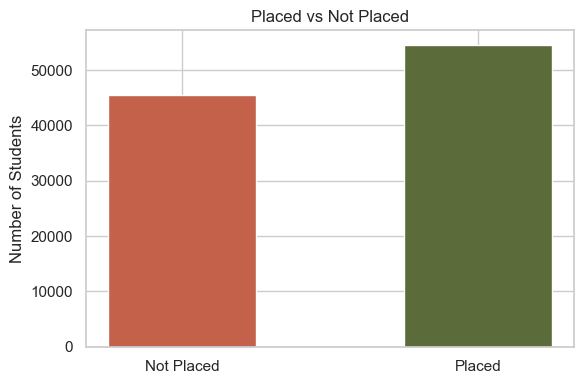

In [10]:
placed_count = len(df[df['placement_status'] == 'Placed'])
not_placed_count = len(df[df['placement_status'] == 'Not Placed'])

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Not Placed', 'Placed'], [not_placed_count, placed_count], color=['#C4614A', '#5C6B3A'], width=0.5)
ax.set_title('Placed vs Not Placed')
ax.set_ylabel('Number of Students')
plt.tight_layout()
plt.show()


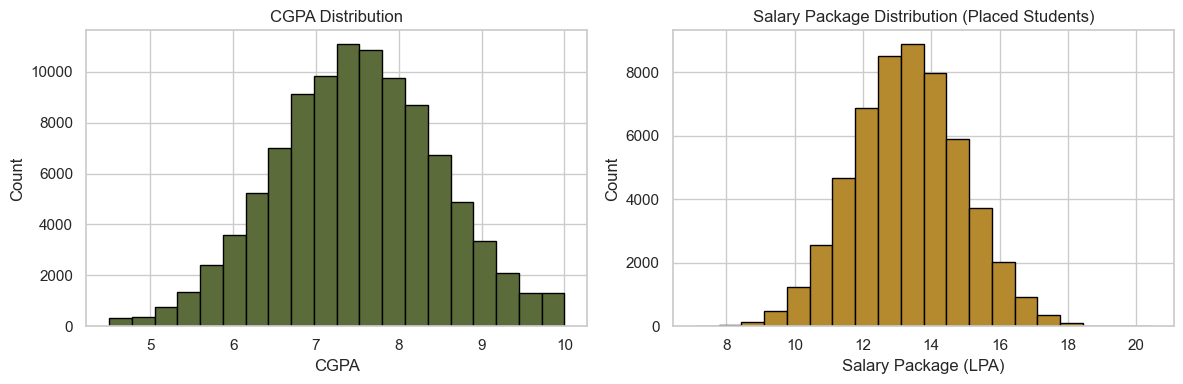

In [11]:
placed_students = df[df['placement_status'] == 'Placed']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['cgpa'], bins=20, color='#5C6B3A', edgecolor='black')
axes[0].set_title('CGPA Distribution')
axes[0].set_xlabel('CGPA')
axes[0].set_ylabel('Count')

axes[1].hist(placed_students['salary_package_lpa'], bins=20, color='#B5892E', edgecolor='black')
axes[1].set_title('Salary Package Distribution (Placed Students)')
axes[1].set_xlabel('Salary Package (LPA)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()


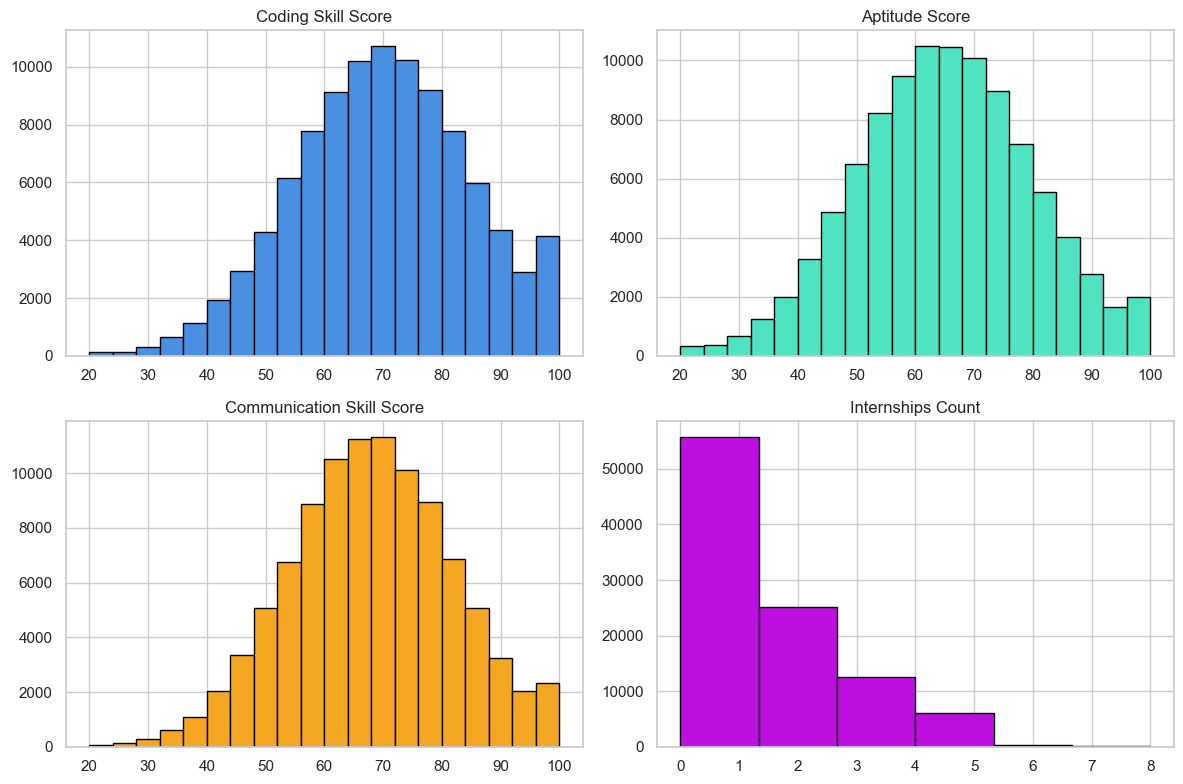

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(df['coding_skill_score'], bins=20, color='#4A90E2', edgecolor='black')
axes[0, 0].set_title('Coding Skill Score')

axes[0, 1].hist(df['aptitude_score'], bins=20, color='#50E3C2', edgecolor='black')
axes[0, 1].set_title('Aptitude Score')

axes[1, 0].hist(df['communication_skill_score'], bins=20, color='#F5A623', edgecolor='black')
axes[1, 0].set_title('Communication Skill Score')

axes[1, 1].hist(df['internships_count'], bins=6, color='#BD10E0', edgecolor='black')
axes[1, 1].set_title('Internships Count')

plt.tight_layout()
plt.show()


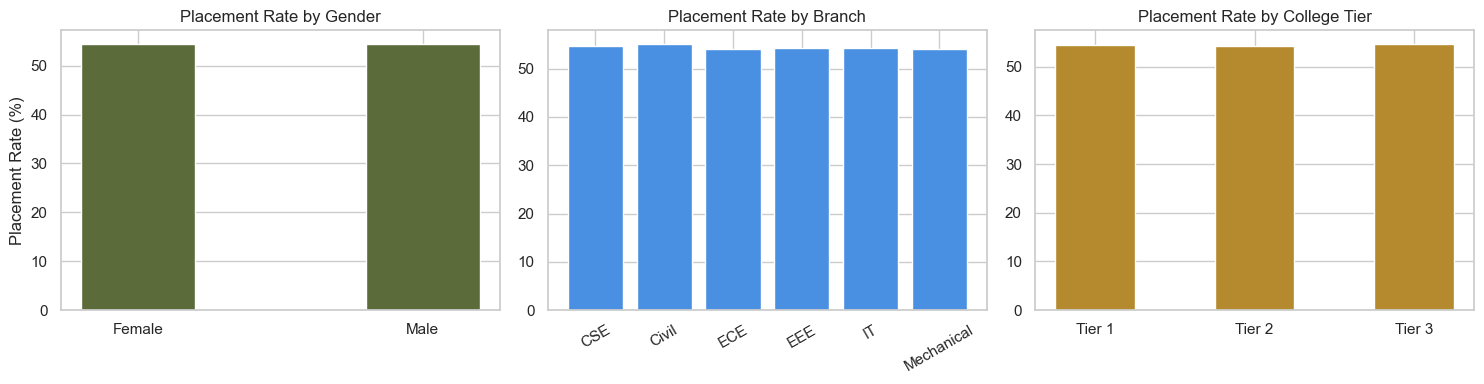

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

gender_rate = df.groupby('gender')['placement_status'].apply(lambda s: (s == 'Placed').mean() * 100).round(2)
axes[0].bar(gender_rate.index, gender_rate.values, color='#5C6B3A', width=0.4)
axes[0].set_title('Placement Rate by Gender')
axes[0].set_ylabel('Placement Rate (%)')

branch_rate = df.groupby('branch')['placement_status'].apply(lambda s: (s == 'Placed').mean() * 100).round(2)
axes[1].bar(branch_rate.index, branch_rate.values, color='#4A90E2')
axes[1].set_title('Placement Rate by Branch')
axes[1].tick_params(axis='x', rotation=30)

tier_rate = df.groupby('college_tier')['placement_status'].apply(lambda s: (s == 'Placed').mean() * 100).round(2)
axes[2].bar(tier_rate.index, tier_rate.values, color='#B5892E', width=0.5)
axes[2].set_title('Placement Rate by College Tier')

plt.tight_layout()
plt.show()


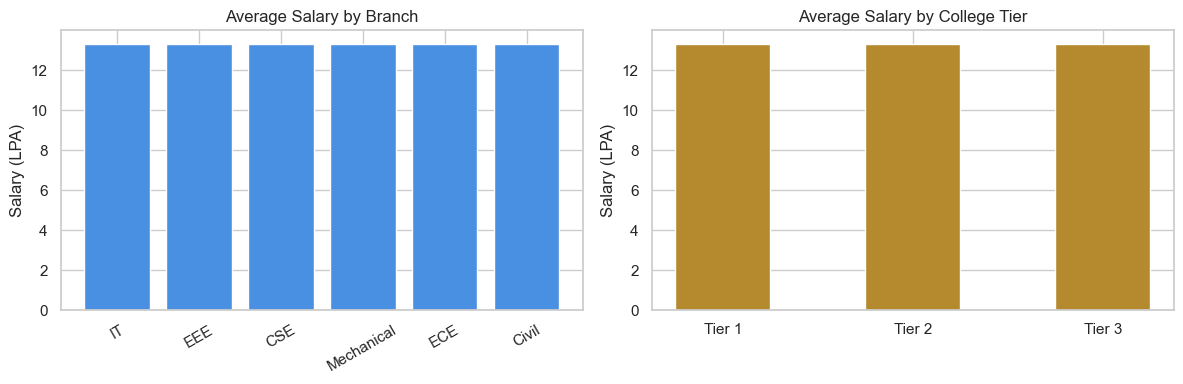

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

branch_salary = placed_students.groupby('branch')['salary_package_lpa'].mean().sort_values(ascending=False)
axes[0].bar(branch_salary.index, branch_salary.values, color='#4A90E2')
axes[0].set_title('Average Salary by Branch')
axes[0].set_ylabel('Salary (LPA)')
axes[0].tick_params(axis='x', rotation=30)

tier_salary = placed_students.groupby('college_tier')['salary_package_lpa'].mean()
axes[1].bar(tier_salary.index, tier_salary.values, color='#B5892E', width=0.5)
axes[1].set_title('Average Salary by College Tier')
axes[1].set_ylabel('Salary (LPA)')

plt.tight_layout()
plt.show()


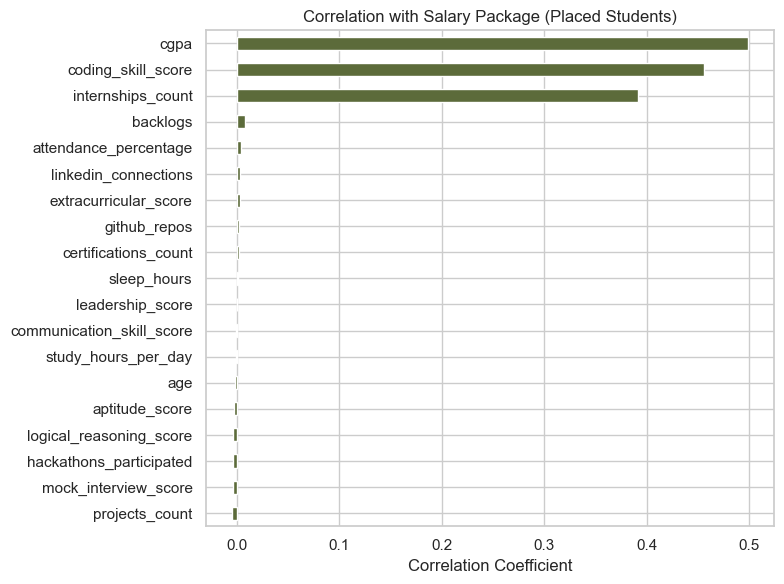

In [15]:
salary_corr = placed_students.corr(numeric_only=True)['salary_package_lpa'].drop(['student_id', 'salary_package_lpa']).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
salary_corr.plot(kind='barh', ax=ax, color='#5C6B3A')
ax.set_title('Correlation with Salary Package (Placed Students)')
ax.set_xlabel('Correlation Coefficient')
plt.tight_layout()
plt.show()


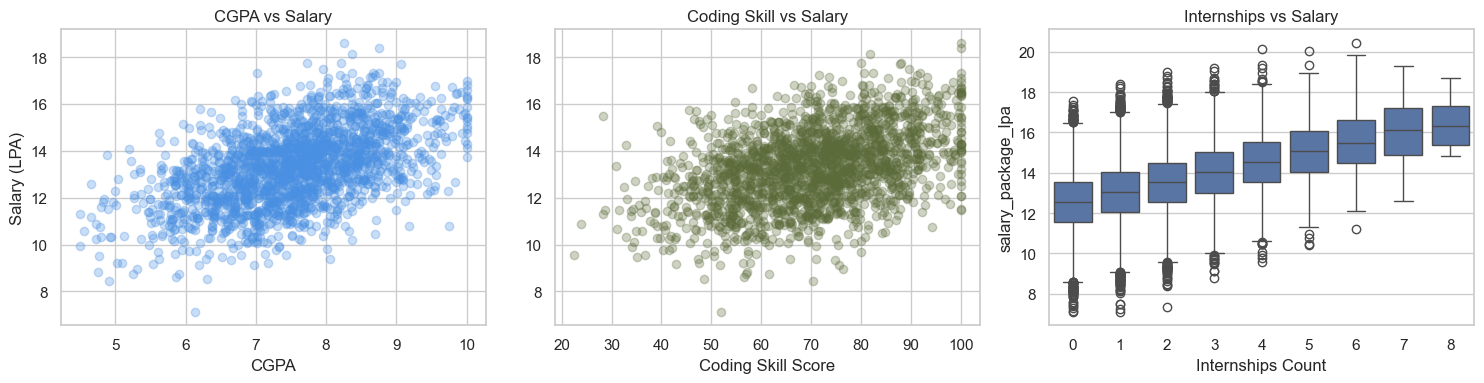

In [16]:
sample_data = placed_students.sample(2000, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(sample_data['cgpa'], sample_data['salary_package_lpa'], alpha=0.3, color='#4A90E2')
axes[0].set_title('CGPA vs Salary')
axes[0].set_xlabel('CGPA')
axes[0].set_ylabel('Salary (LPA)')

axes[1].scatter(sample_data['coding_skill_score'], sample_data['salary_package_lpa'], alpha=0.3, color='#5C6B3A')
axes[1].set_title('Coding Skill vs Salary')
axes[1].set_xlabel('Coding Skill Score')

sns.boxplot(x='internships_count', y='salary_package_lpa', data=placed_students, ax=axes[2])
axes[2].set_title('Internships vs Salary')
axes[2].set_xlabel('Internships Count')

plt.tight_layout()
plt.show()


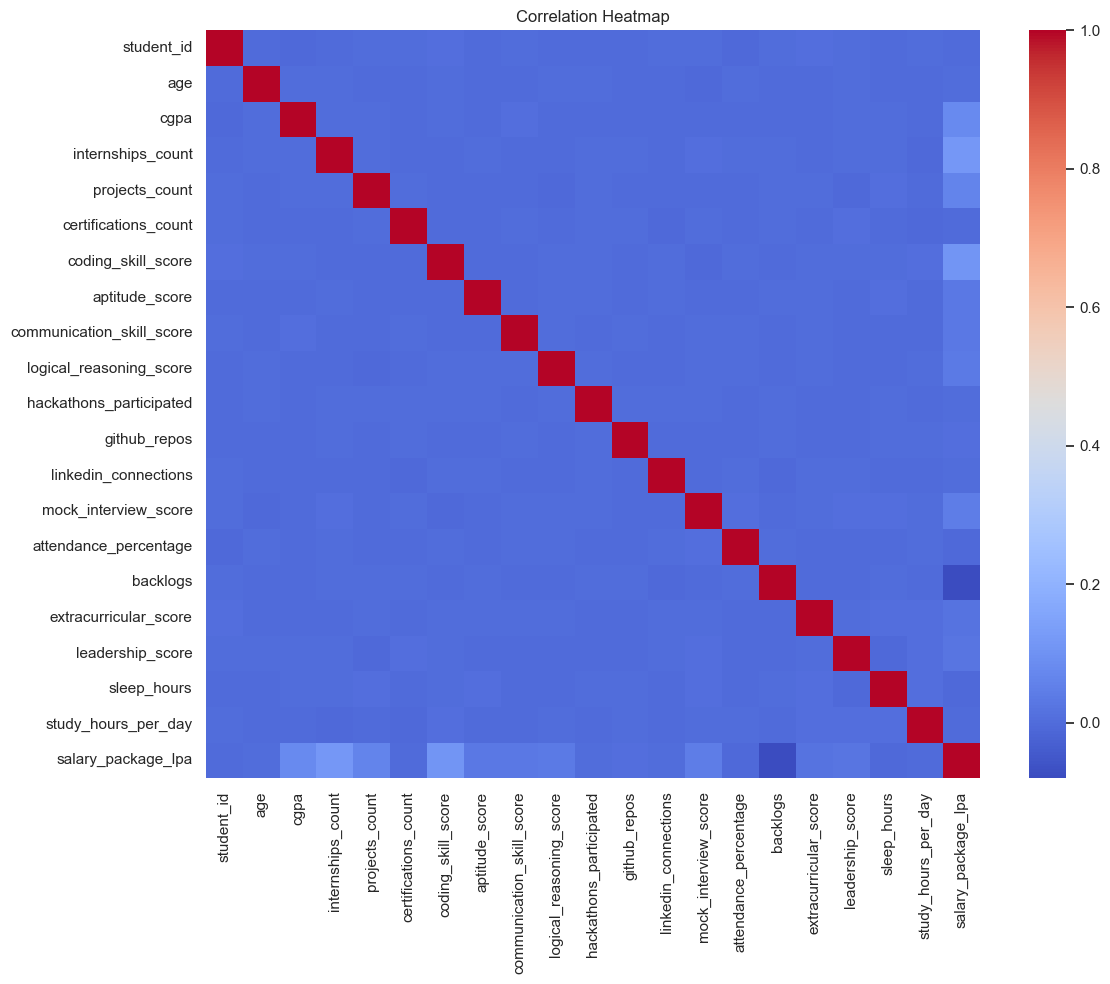

In [17]:
corr_matrix = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, ax=ax)
ax.set_title('Correlation Heatmap')
plt.tight_layout()
plt.show()


In [18]:
mean_comparison = df.groupby('placement_status').mean(numeric_only=True).T
print(mean_comparison.round(2))


placement_status           Not Placed    Placed
student_id                   50026.41  49978.83
age                             21.00     21.01
cgpa                             7.48      7.51
internships_count                1.42      1.57
projects_count                   2.89      3.10
certifications_count             2.01      2.00
coding_skill_score              69.01     70.51
aptitude_score                  64.47     65.42
communication_skill_score       67.47     68.37
logical_reasoning_score         65.34     66.42
hackathons_participated          1.00      1.00
github_repos                     3.99      4.01
linkedin_connections           523.59    525.37
mock_interview_score            69.39     70.49
attendance_percentage           84.82     84.66
backlogs                         0.56      0.44
extracurricular_score           59.46     60.25
leadership_score                54.46     55.34
sleep_hours                      6.99      6.98
study_hours_per_day              3.53   

In [19]:
q1 = placed_students['salary_package_lpa'].quantile(0.25)
q3 = placed_students['salary_package_lpa'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = placed_students[(placed_students['salary_package_lpa'] < lower_bound) | (placed_students['salary_package_lpa'] > upper_bound)]
print('Q1:', round(q1, 2))
print('Q3:', round(q3, 2))
print('IQR:', round(iqr, 2))
print('Lower bound:', round(lower_bound, 2))
print('Upper bound:', round(upper_bound, 2))
print('Outliers count:', len(outliers))


Q1: 12.23
Q3: 14.39
IQR: 2.16
Lower bound: 8.99
Upper bound: 17.63
Outliers count: 318


# Part 3: Data Preprocessing


In [20]:
print('Missing values before:', df.isnull().sum().sum())
df = df.fillna(df.mean(numeric_only=True))
print('Missing values after:', df.isnull().sum().sum())


Missing values before: 0
Missing values after: 0


In [21]:
print('Duplicate rows before:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicate rows after:', df.duplicated().sum())


Duplicate rows before: 0
Duplicate rows after: 0


In [22]:
from sklearn.preprocessing import LabelEncoder

le_gender = LabelEncoder()
df['gender'] = le_gender.fit_transform(df['gender'].astype(str))

le_branch = LabelEncoder()
df['branch'] = le_branch.fit_transform(df['branch'].astype(str))

le_tier = LabelEncoder()
df['college_tier'] = le_tier.fit_transform(df['college_tier'].astype(str))

le_volunteer = LabelEncoder()
df['volunteer_experience'] = le_volunteer.fit_transform(df['volunteer_experience'].astype(str))

le_status = LabelEncoder()
df['placement_status'] = le_status.fit_transform(df['placement_status'].astype(str))

encoders = {
    'gender': le_gender,
    'branch': le_branch,
    'college_tier': le_tier,
    'volunteer_experience': le_volunteer,
    'placement_status': le_status
}


In [23]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   student_id                 100000 non-null  int64  
 1   age                        100000 non-null  int64  
 2   gender                     100000 non-null  int64  
 3   cgpa                       100000 non-null  float64
 4   branch                     100000 non-null  int64  
 5   college_tier               100000 non-null  int64  
 6   internships_count          100000 non-null  int64  
 7   projects_count             100000 non-null  int64  
 8   certifications_count       100000 non-null  int64  
 9   coding_skill_score         100000 non-null  float64
 10  aptitude_score             100000 non-null  float64
 11  communication_skill_score  100000 non-null  float64
 12  logical_reasoning_score    100000 non-null  float64
 13  hackathons_participated    100

In [24]:
import os
import pickle

os.makedirs('../models', exist_ok=True)
with open('../models/encoders.pkl', 'wb') as f:
    pickle.dump(encoders, f)
print('Encoders saved successfully to ../models/encoders.pkl')


Encoders saved successfully to ../models/encoders.pkl


In [25]:
os.makedirs('../datasets/processed', exist_ok=True)
df.to_csv('../datasets/processed/encoded_data.csv', index=False)
print('Encoded dataset saved with shape:', df.shape)


Encoded dataset saved with shape: (100000, 26)


# Part 4: Feature Engineering and Selection


In [26]:
placed_code = encoders['placement_status'].transform(['Placed'])[0]
salary_df = df[df['placement_status'] == placed_code].copy()
print('Total placed students for salary prediction:', len(salary_df))


Total placed students for salary prediction: 54459


In [27]:
selected_features = [
    'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count',
    'certifications_count', 'coding_skill_score', 'aptitude_score',
    'communication_skill_score', 'mock_interview_score',
    'attendance_percentage', 'backlogs'
]
print('Selected features count:', len(selected_features))
print('Features:', selected_features)


Selected features count: 12
Features: ['cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'mock_interview_score', 'attendance_percentage', 'backlogs']


In [28]:
from sklearn.ensemble import RandomForestRegressor

sample_rf = salary_df.sample(20000, random_state=42)
rf_selector = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_selector.fit(sample_rf[selected_features], sample_rf['salary_package_lpa'])

importance_df = pd.DataFrame({
    'Feature': selected_features,
    'Importance': rf_selector.feature_importances_
}).sort_values('Importance', ascending=False)
print(importance_df.round(4))


                      Feature  Importance
0                        cgpa      0.3750
6          coding_skill_score      0.3070
3           internships_count      0.2115
7              aptitude_score      0.0216
9        mock_interview_score      0.0198
8   communication_skill_score      0.0193
10      attendance_percentage      0.0189
4              projects_count      0.0081
5        certifications_count      0.0075
1                      branch      0.0054
2                college_tier      0.0031
11                   backlogs      0.0030


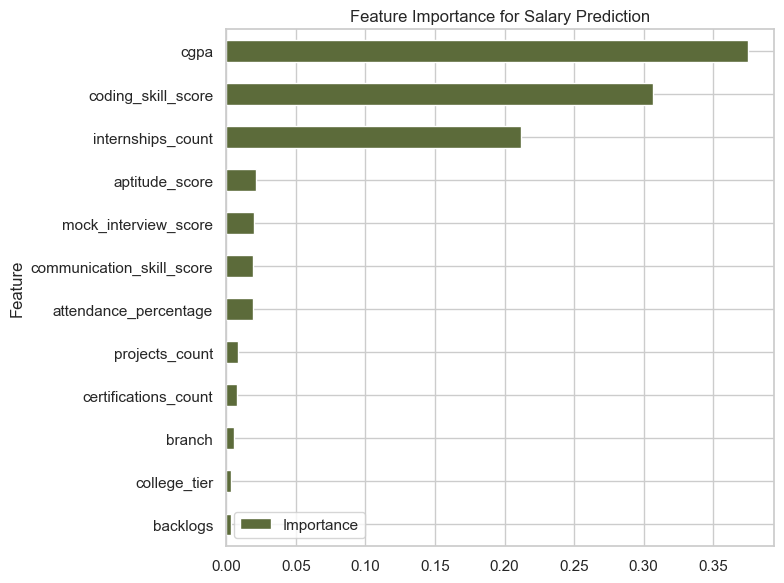

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))
importance_df.sort_values('Importance').plot(x='Feature', y='Importance', kind='barh', ax=ax, color='#5C6B3A')
ax.set_title('Feature Importance for Salary Prediction')
plt.tight_layout()
plt.show()


In [30]:
from sklearn.model_selection import train_test_split

X = salary_df[selected_features]
y = salary_df['salary_package_lpa']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('Training data shape:', X_train.shape)
print('Testing data shape:', X_test.shape)


Training data shape: (43567, 12)
Testing data shape: (10892, 12)


In [31]:
import json

X_train.to_csv('../datasets/processed/X_train.csv', index=False)
X_test.to_csv('../datasets/processed/X_test.csv', index=False)
y_train.to_csv('../datasets/processed/y_train.csv', index=False)
y_test.to_csv('../datasets/processed/y_test.csv', index=False)

with open('../models/feature_columns.json', 'w') as f:
    json.dump(selected_features, f)

print('Splits and feature list saved successfully.')


Splits and feature list saved successfully.


# Part 5: Model Training


In [32]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
print('Linear Regression model training completed.')


Linear Regression model training completed.


## Train Decision Tree Model


In [33]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(max_depth=12, random_state=42)
dt_model.fit(X_train, y_train)
print('Decision Tree model training completed.')


Decision Tree model training completed.


## Train Random Forest Model


In [34]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=50, max_depth=8, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest model training completed.")

Random Forest model training completed.


## Save Trained Models


In [35]:
with open('../models/linear_regression.pkl', 'wb') as f:
    pickle.dump(lr_model, f)

with open('../models/decision_tree.pkl', 'wb') as f:
    pickle.dump(dt_model, f)

with open('../models/random_forest.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

print('All models saved successfully in ../models folder.')


All models saved successfully in ../models folder.


# Part 6: Model Evaluation


In [36]:
y_pred_lr = lr_model.predict(X_test)
y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)
print('Predictions generated for all models.')


Predictions generated for all models.


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

metrics_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_dt),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    'MSE': [
        mean_squared_error(y_test, y_pred_lr),
        mean_squared_error(y_test, y_pred_dt),
        mean_squared_error(y_test, y_pred_rf)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_dt)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_dt),
        r2_score(y_test, y_pred_rf)
    ]
})

metrics_df.to_csv('../models/model_metrics.csv', index=False)
print(metrics_df.round(4))


               Model     MAE     MSE    RMSE  R2 Score
0  Linear Regression  0.7983  0.9978  0.9989    0.6061
1      Decision Tree  0.9128  1.3433  1.1590    0.4697
2      Random Forest  0.8085  1.0271  1.0135    0.5945


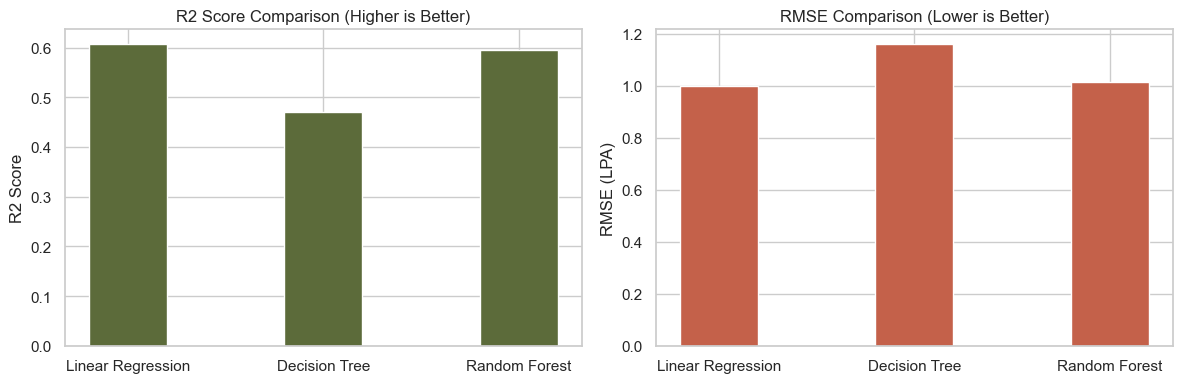

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(metrics_df['Model'], metrics_df['R2 Score'], color='#5C6B3A', width=0.4)
axes[0].set_title('R2 Score Comparison (Higher is Better)')
axes[0].set_ylabel('R2 Score')

axes[1].bar(metrics_df['Model'], metrics_df['RMSE'], color='#C4614A', width=0.4)
axes[1].set_title('RMSE Comparison (Lower is Better)')
axes[1].set_ylabel('RMSE (LPA)')

plt.tight_layout()
plt.show()


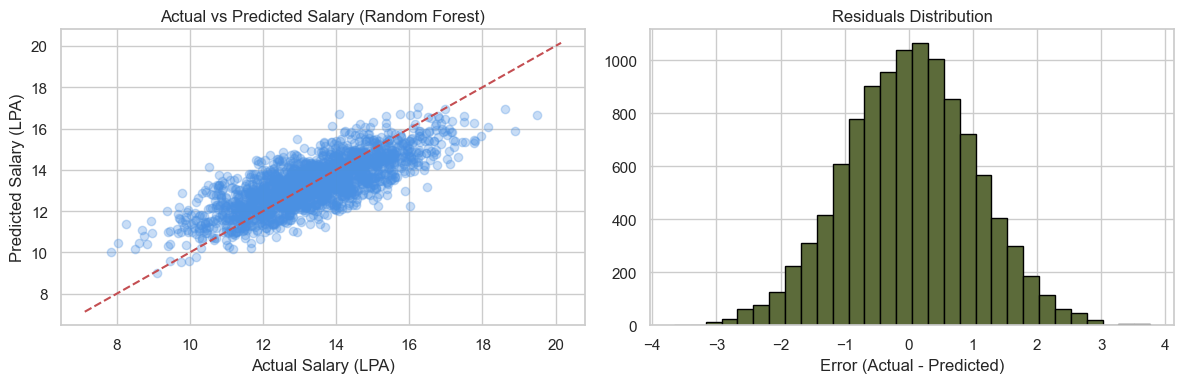

In [39]:
sample_indices = np.random.RandomState(42).choice(len(y_test), 2000, replace=False)
y_sample_actual = y_test.iloc[sample_indices]
y_sample_pred = y_pred_rf[sample_indices]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_sample_actual, y_sample_pred, alpha=0.3, color='#4A90E2')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_title('Actual vs Predicted Salary (Random Forest)')
axes[0].set_xlabel('Actual Salary (LPA)')
axes[0].set_ylabel('Predicted Salary (LPA)')

residuals = y_test - y_pred_rf
axes[1].hist(residuals, bins=30, color='#5C6B3A', edgecolor='black')
axes[1].set_title('Residuals Distribution')
axes[1].set_xlabel('Error (Actual - Predicted)')

plt.tight_layout()
plt.show()


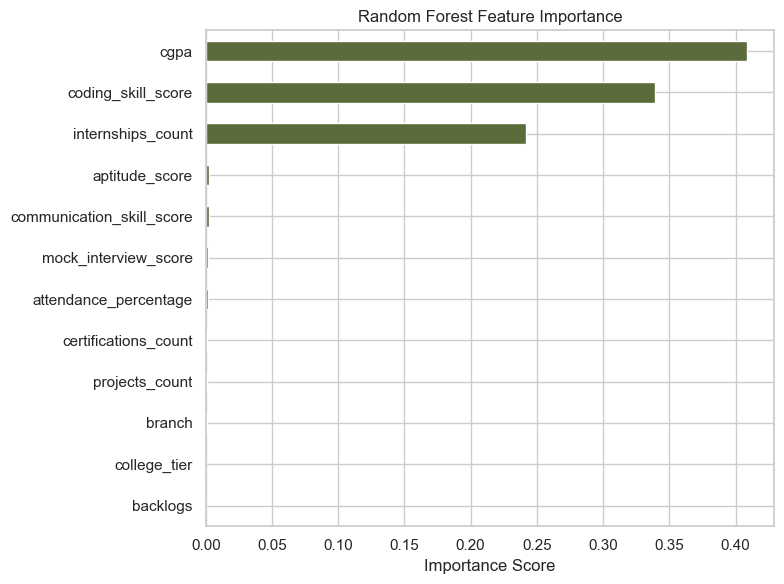

In [40]:
fi_series = pd.Series(rf_model.feature_importances_, index=selected_features).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
fi_series.plot(kind='barh', ax=ax, color='#5C6B3A')
ax.set_title('Random Forest Feature Importance')
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.show()


# Part 7: Streamlit Dashboard


In [41]:
print('To run the Streamlit dashboard, open your terminal and run:')
print('cd placement_prediction/dashboard')
print('streamlit run main.py')


To run the Streamlit dashboard, open your terminal and run:
cd placement_prediction/dashboard
streamlit run main.py
